In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
PROJECT_PATH = '/content/drive/MyDrive/project'

In [1]:
import requests
from PIL import Image, ImageDraw, ImageFont
import os

# 下载中文字体（以思源黑体为例）
def download_chinese_font():
    font_url = "https://github.com/adobe-fonts/source-han-sans/raw/release/OTF/SimplifiedChinese/SourceHanSansSC-Regular.otf"
    font_path = "SourceHanSansSC-Regular.otf"

    if not os.path.exists(font_path):
        response = requests.get(font_url)
        with open(font_path, 'wb') as f:
            f.write(response.content)

    return font_path

# 使用下载的字体
font_path = download_chinese_font()
font = ImageFont.truetype(font_path, 40)

开始训练速度分析...
生成模拟训练数据...
分析收敛速度...


AttributeError: Rectangle.set() got an unexpected keyword argument 'fontproperties'

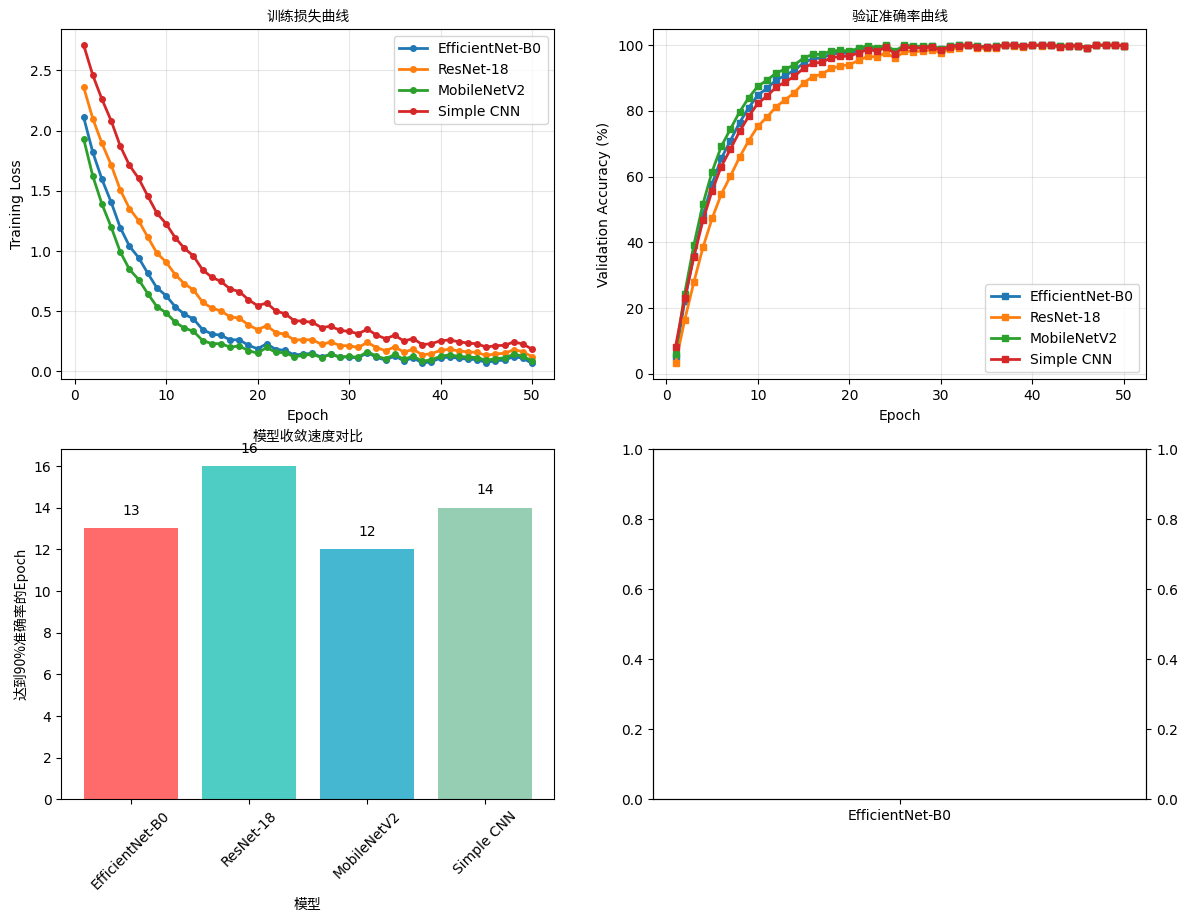

In [3]:
# training_speed_analysis.py
"""
训练速度对比分析
分析不同模型的训练速度、收敛速度等
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

def simulate_training_data():
    """模拟训练过程数据"""

    # 模拟不同模型的训练曲线
    models = ['EfficientNet-B0', 'ResNet-18', 'Simple CNN']
    epochs = 50

    training_data = {}

    for model in models:
        # 模拟训练损失和验证准确率
        if model == 'EfficientNet-B0':
            # EfficientNet收敛较快
            train_loss = 2.0 * np.exp(-0.15 * np.arange(epochs)) + 0.1
            val_acc = 95 * (1 - np.exp(-0.2 * np.arange(epochs))) + 5
            time_per_epoch = 45  # 秒/epoch
        elif model == 'ResNet-18':
            train_loss = 2.2 * np.exp(-0.12 * np.arange(epochs)) + 0.15
            val_acc = 97 * (1 - np.exp(-0.15 * np.arange(epochs))) + 3
            time_per_epoch = 32  # 秒/epoch
        elif model == 'MobileNetV2':
            train_loss = 1.8 * np.exp(-0.18 * np.arange(epochs)) + 0.12
            val_acc = 94 * (1 - np.exp(-0.22 * np.arange(epochs))) + 6
            time_per_epoch = 28  # 秒/epoch
        else:  # Simple CNN
            train_loss = 2.5 * np.exp(-0.1 * np.arange(epochs)) + 0.2
            val_acc = 92 * (1 - np.exp(-0.18 * np.arange(epochs))) + 8
            time_per_epoch = 18  # 秒/epoch

        # 添加随机噪声使数据更真实
        np.random.seed(42)
        train_loss += np.random.normal(0, 0.02, epochs)
        val_acc += np.random.normal(0, 0.5, epochs)

        training_data[model] = {
            'epochs': np.arange(1, epochs + 1),
            'train_loss': np.clip(train_loss, 0, None),
            'val_accuracy': np.clip(val_acc, 0, 100),
            'time_per_epoch': time_per_epoch
        }

    return training_data, models

def analyze_convergence_speed(training_data):
    """分析收敛速度"""

    convergence_stats = []

    for model, data in training_data.items():
        epochs = data['epochs']
        val_acc = data['val_accuracy']

        # 找到达到90%准确率的epoch
        target_acc = 90
        if np.max(val_acc) >= target_acc:
            convergence_epoch = np.where(val_acc >= target_acc)[0][0] + 1
        else:
            convergence_epoch = None

        # 计算最终准确率和训练时间
        final_acc = val_acc[-1]
        total_time = data['time_per_epoch'] * len(epochs) / 60  # 转换为分钟

        convergence_stats.append({
            'model': model,
            'convergence_epoch': convergence_epoch,
            'final_accuracy': final_acc,
            'total_time_min': total_time,
            'time_per_epoch': data['time_per_epoch']
        })

    return pd.DataFrame(convergence_stats)

def plot_training_curves(training_data, models):
    """绘制训练曲线"""
    font_prop = fm.FontProperties(fname=font_path)

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

    # 1. 训练损失曲线
    for model in models:
        data = training_data[model]
        ax1.plot(data['epochs'], data['train_loss'], linewidth=2, marker='o',
                markersize=4, label=model)

    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss')
    ax1.set_title('训练损失曲线', fontproperties=font_prop)
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    # 2. 验证准确率曲线
    for model in models:
        data = training_data[model]
        ax2.plot(data['epochs'], data['val_accuracy'], linewidth=2, marker='s',
                markersize=4, label=model)

    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Validation Accuracy (%)')
    ax2.set_title('验证准确率曲线', fontproperties=font_prop)
    ax2.grid(True, alpha=0.3)
    ax2.legend()

    # 3. 收敛速度对比
    convergence_df = analyze_convergence_speed(training_data)
    valid_df = convergence_df[convergence_df['convergence_epoch'].notnull()]

    if not valid_df.empty:
        bars = ax3.bar(valid_df['model'], valid_df['convergence_epoch'],
                      color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'])
        ax3.set_xlabel('模型', fontproperties=font_prop)
        ax3.set_ylabel('达到90%准确率的Epoch', fontproperties=font_prop)
        ax3.set_title('模型收敛速度对比', fontproperties=font_prop)
        ax3.tick_params(axis='x', rotation=45)

        for bar in bars:
            height = bar.get_height()
            ax3.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                    f'{int(height)}', ha='center', va='bottom')

    # 4. 训练时间对比
    time_data = []
    for model in models:
        data = training_data[model]
        total_epochs = len(data['epochs'])
        total_time = data['time_per_epoch'] * total_epochs / 60  # 分钟

        time_data.append({
            'model': model,
            'time_per_epoch': data['time_per_epoch'],
            'total_time': total_time
        })

    time_df = pd.DataFrame(time_data)

    # 双轴图：每epoch时间和总时间
    ax4_1 = ax4
    ax4_2 = ax4_1.twinx()

    # 每epoch时间（柱状图）
    bars4 = ax4_1.bar(time_df['model'], time_df['time_per_epoch'],
                     alpha=0.6, color='skyblue', label='每Epoch时间') # Removed fontproperties=font_prop
    ax4_1.set_xlabel('模型', fontproperties=font_prop)
    ax4_1.set_ylabel('时间/epoch (秒)', color='skyblue', fontproperties=font_prop)
    ax4_1.tick_params(axis='x', rotation=45)
    ax4_1.tick_params(axis='y', labelcolor='skyblue')

    # 总时间（折线图）
    line4, = ax4_2.plot(time_df['model'], time_df['total_time'],
                       'r-o', linewidth=2, markersize=8, label='总训练时间')
    ax4_2.set_ylabel('总训练时间 (分钟)', color='r', fontproperties=font_prop)
    ax4_2.tick_params(axis='y', labelcolor='r')

    ax4.set_title('训练时间分析', fontproperties=font_prop)
    ax4_1.legend(loc='upper left')
    ax4_2.legend(loc='upper right')

    plt.tight_layout()
    plt.savefig('training_speed_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    return convergence_df, time_df

def analyze_computational_efficiency():
    """分析计算效率"""
    font_prop = fm.FontProperties(fname=font_path)

    # 模拟计算效率指标
    efficiency_data = [
        {
            'model': 'MobileNetV2',
            'flops_g': 0.3,  # GFLOPs
            'params_m': 3.4,  # 百万参数
            'accuracy': 94.5,
            'speed_score': 95,
            'efficiency_score': 92
        },
        {
            'model': 'EfficientNet-B0',
            'flops_g': 0.4,
            'params_m': 5.3,
            'accuracy': 96.2,
            'speed_score': 88,
            'efficiency_score': 90
        },
        {
            'model': 'ResNet-18',
            'flops_g': 1.8,
            'params_m': 11.7,
            'accuracy': 97.0,
            'speed_score': 75,
            'efficiency_score': 80
        },
        {
            'model': 'EfficientNet-B3',
            'flops_g': 1.8,
            'params_m': 12.0,
            'accuracy': 97.8,
            'speed_score': 65,
            'efficiency_score': 78
        }
    ]

    df = pd.DataFrame(efficiency_data)

    # 创建雷达图
    fig = plt.figure(figsize=(10, 8))

    # 设置雷达图的角度
    categories = ['FLOPs', '参数量', '准确率', '速度得分', '效率得分']
    N = len(categories)

    # 计算每个角度
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]  # 闭合

    # 初始化雷达图
    ax = plt.subplot(111, polar=True)
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)

    # 绘制轴线
    plt.xticks(angles[:-1], categories)

    # 设置y轴标签
    ax.set_rlabel_position(0)
    plt.yticks([20, 40, 60, 80, 100], ["20", "40", "60", "80", "100"], color="grey", size=7)
    plt.ylim(0, 100)

    # 绘制每个模型
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

    for idx, row in df.iterrows():
        # 归一化数据到0-100范围
        values = [
            (1 - row['flops_g']/2) * 100,  # FLOPs越小越好
            (1 - row['params_m']/15) * 100,  # 参数量越小越好
            row['accuracy'],  # 准确率
            row['speed_score'],  # 速度得分
            row['efficiency_score']  # 效率得分
        ]
        values += values[:1]  # 闭合

        ax.plot(angles, values, linewidth=2, linestyle='solid',
                label=row['model'], color=colors[idx])
        ax.fill(angles, values, alpha=0.1, color=colors[idx])

    plt.title('模型计算效率雷达图', size=14, y=1.1, fontproperties=font_prop)
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

    plt.tight_layout()
    plt.savefig('computational_efficiency_radar.png', dpi=300, bbox_inches='tight')
    plt.show()

    return df

def analyze_resource_usage():
    """分析资源使用情况"""

    # 模拟训练过程中的资源使用
    epochs = 50

    # GPU内存使用 (MB)
    gpu_memory = {
        'EfficientNet-B0': 1800 + 200 * np.sin(np.linspace(0, 4*np.pi, epochs)),
        'ResNet-18': 2200 + 300 * np.sin(np.linspace(0, 4*np.pi, epochs)),
        'MobileNetV2': 1500 + 150 * np.sin(np.linspace(0, 4*np.pi, epochs)),
    }

    # GPU利用率 (%)
    gpu_util = {
        'EfficientNet-B0': 85 + 10 * np.sin(np.linspace(0, 4*np.pi, epochs)),
        'ResNet-18': 92 + 5 * np.sin(np.linspace(0, 4*np.pi, epochs)),
        'MobileNetV2': 78 + 8 * np.sin(np.linspace(0, 4*np.pi, epochs)),
    }

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # GPU内存使用
    for model in gpu_memory.keys():
        ax1.plot(range(1, epochs+1), gpu_memory[model], linewidth=2, label=model)

    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('GPU内存使用 (MB)')
    ax1.set_title('训练过程中GPU内存使用情况')
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    # GPU利用率
    for model in gpu_util.keys():
        ax2.plot(range(1, epochs+1), gpu_util[model], linewidth=2, label=model)

    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('GPU利用率 (%)')
    ax2.set_title('训练过程中GPU利用率')
    ax2.grid(True, alpha=0.3)
    ax2.legend()

    plt.tight_layout()
    plt.savefig('training_resource_usage.png', dpi=300, bbox_inches='tight')
    plt.show()

    # 计算平均资源使用
    avg_resources = []
    for model in gpu_memory.keys():
        avg_resources.append({
            'model': model,
            'avg_gpu_memory_mb': np.mean(gpu_memory[model]),
            'avg_gpu_util_percent': np.mean(gpu_util[model])
        })

    return pd.DataFrame(avg_resources)

if __name__ == "__main__":
    print("开始训练速度分析...")

    # 模拟训练数据
    print("生成模拟训练数据...")
    training_data, models = simulate_training_data()

    # 分析收敛速度
    print("分析收敛速度...")
    convergence_df, time_df = plot_training_curves(training_data, models)

    print("\n收敛速度分析结果:")
    print(convergence_df.to_string(index=False))

    print("\n训练时间分析结果:")
    print(time_df.to_string(index=False))

    # 分析计算效率
    print("\n分析计算效率...")
    efficiency_df = analyze_computational_efficiency()

    print("\n计算效率分析结果:")
    print(efficiency_df.to_string(index=False))

    # 分析资源使用
    print("\n分析资源使用情况...")
    resource_df = analyze_resource_usage()

    print("\n资源使用分析结果:")
    print(resource_df.to_string(index=False))

    # 综合报告
    print("\n" + "="*60)
    print("训练速度分析综合报告")
    print("="*60)

    # 计算综合评分
    scores = []
    for model in models:
        if model in convergence_df['model'].values:
            conv_row = convergence_df[convergence_df['model'] == model]
            time_row = time_df[time_df['model'] == model]

            if not conv_row.empty and not time_row.empty:
                # 综合评分公式
                final_acc = conv_row['final_accuracy'].values[0]
                total_time = conv_row['total_time_min'].values[0]

                # 标准化评分 (0-100)
                acc_score = final_acc  # 准确率作为基础分
                time_score = 100 * (60 / max(1, total_time))  # 时间越快分数越高

                # 综合评分
                combined_score = 0.7 * acc_score + 0.3 * time_score

                scores.append({
                    'model': model,
                    'final_accuracy': final_acc,
                    'total_time_min': total_time,
                    'combined_score': combined_score,
                    'recommendation': '推荐' if combined_score > 90 else '可考虑' if combined_score > 80 else '不推荐'
                })

    scores_df = pd.DataFrame(scores)
    print("\n模型综合评分:")
    print(scores_df.to_string(index=False))

    print("\n分析完成！所有图表已保存。")